# 00 · Setup `[local]`

**Goal:** get your environment working and learn the habits every later notebook relies on.

By the end you will have:
1. Run the standard first cell that every notebook starts with.
2. Checked that PyTorch can use your Mac's GPU (Apple **MPS**).
3. Loaded and displayed your first image with OpenCV.
4. Set up Kaggle for the GPU-heavy notebooks later in the course.

---
## How to open these notebooks

From the project folder in a terminal:

```bash
uv sync                 # install/update everything in pyproject.toml (first time, or after changes)
uv run jupyter lab      # opens Jupyter in your browser
```

Or in **VS Code / Cursor**: open a notebook, click *Select Kernel* (top right) → *Python Environments* → `.venv`.

**Why Python 3.12 and not your system's 3.14?** CV libraries ship pre-built binaries for a few Python versions, and the newest Python is usually not supported yet. `uv` keeps a separate 3.12 just for this project in the `.venv` folder.

## Project layout

```
cv-mastery/
├── PLAN.md          the course plan
├── README.md        progress checklist
├── notebooks/       one folder per module
├── cvlib/           your reusable code: grows as you go
├── data/            downloads and outputs (not committed)
└── notes/           your own cheat sheets
```

## 1 · The standard first cell

Every notebook starts with this cell. It:
- **finds `cvlib`** by walking up from the notebook's folder (on Kaggle it looks in attached datasets instead),
- **detects the platform** (your Mac, Kaggle or Colab) and picks the right data folder,
- **picks the device**: `cuda` (NVIDIA GPU) → `mps` (Apple GPU) → `cpu`,
- **seeds the random number generators**, so you get the same results every run.

In [1]:
# ── Standard first cell: finds cvlib, picks the device, seeds randomness ──
import sys, pathlib
for _p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, *pathlib.Path("/kaggle/input").glob("*")]:
    if (_p / "cvlib").is_dir():
        sys.path.insert(0, str(_p)); break
from cvlib.env import setup
env = setup()

platform=local | device=mps | python=3.12.12 | numpy=2.5.4 | cv2=5.0.0 | torch=2.15.0
data_dir=/Users/abhijeet/Personal/cv-mastery/data


`env` is a small object you'll use everywhere:

In [2]:
print("platform :", env.platform)
print("device   :", env.device)
print("data_dir :", env.data_dir)
print("out_dir  :", env.out_dir)

platform : local
device   : mps
data_dir : /Users/abhijeet/Personal/cv-mastery/data
out_dir  : /Users/abhijeet/Personal/cv-mastery/data/outputs


## 2 · Is the GPU working?

A GPU is thousands of small, simple calculators working in parallel. Deep learning is mostly huge matrix multiplications, which split perfectly across them.

Let's multiply two big matrices on the CPU and on the GPU and compare.

> **Timing GPU code correctly:** the GPU runs *asynchronously*. Python hands it work and moves on immediately. To time it honestly you must wait for it to finish (`torch.mps.synchronize()`), and do one "warm-up" run first, because the first call includes one-time setup costs. You'll use this again in module 15.

In [3]:
import time
import torch

def time_matmul(device, n=2048, repeats=10):
    a = torch.randn(n, n, device=device)
    b = torch.randn(n, n, device=device)
    sync = {"mps": torch.mps.synchronize, "cuda": torch.cuda.synchronize}.get(device, lambda: None)
    a @ b; sync()                                 # warm-up
    start = time.perf_counter()
    for _ in range(repeats):
        a @ b
    sync()                                        # wait for the GPU to finish
    return (time.perf_counter() - start) / repeats * 1000

cpu_ms = time_matmul("cpu")
print(f"cpu : {cpu_ms:7.1f} ms per 2048×2048 matmul")
if env.device != "cpu":
    gpu_ms = time_matmul(env.device)
    print(f"{env.device:4}: {gpu_ms:7.1f} ms per 2048×2048 matmul  → {cpu_ms / gpu_ms:.1f}× faster")

cpu :    12.4 ms per 2048×2048 matmul
mps :    10.7 ms per 2048×2048 matmul  → 1.2× faster


Apple's CPUs are fast at matrix math too, so the gap here is smaller than on an NVIDIA GPU. It grows with bigger models, and training a network involves millions of these operations.

**Your Mac has 8 GB of memory shared between CPU and GPU.** Local notebooks keep datasets and models small. Anything heavier is marked `[kaggle]`.

## 3 · First image with OpenCV

`cvlib.data.opencv_sample()` downloads a sample image from OpenCV's GitHub once and caches it in `data/`.
`cvlib.viz.show()` displays one or more images.

file : /Users/abhijeet/Personal/cv-mastery/data/opencv_samples/fruits.jpg
type : <class 'numpy.ndarray'> | dtype: uint8 | shape (height, width, channels): (480, 512, 3)


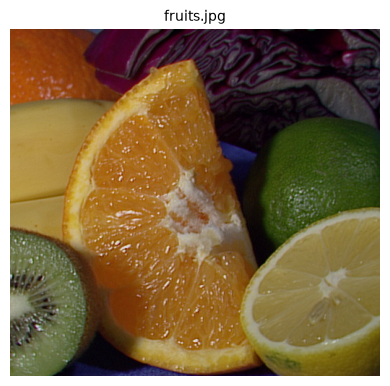

In [4]:
import cv2
from cvlib.data import opencv_sample
from cvlib.viz import show

path = opencv_sample("fruits.jpg")
img = cv2.imread(str(path))
print("file :", path)
print("type :", type(img), "| dtype:", img.dtype, "| shape (height, width, channels):", img.shape)
show(img, "fruits.jpg")

That's it: **an image is just a NumPy array of numbers**. Module 01 starts from exactly here.

## 4 · Kaggle setup (for later modules)

You won't need Kaggle in Phase 1, but set it up now so it's ready.

**Account**
1. Sign up at [kaggle.com](https://www.kaggle.com).
2. *Settings → Phone verification.* Required to turn on **internet** and **GPUs** in notebooks.

**Running a notebook on Kaggle**
1. *Create → New Notebook → File → Import Notebook*, and upload the `.ipynb` file.
2. Right panel → *Session options*: **Accelerator: GPU T4 x2**, **Internet: On**.
3. For long training runs, use **Save Version → Save & Run All (Commit)**. It keeps running after you close the tab.

**Making `cvlib` available on Kaggle**
1. Zip the `cvlib` folder: `zip -r cvlib.zip cvlib` from the project root.
2. Kaggle → *Datasets → New Dataset*, upload `cvlib.zip`, name it `cvlib`, keep it private.
3. In a Kaggle notebook: *Add Input → Your Datasets → cvlib*.
4. The standard first cell finds it automatically. Re-upload a new version when you change `cvlib`.

**Optional: the Kaggle command line**
```bash
uv pip install kaggle
# Kaggle → Settings → API → Create New Token, then move the downloaded file:
mkdir -p ~/.kaggle && mv ~/Downloads/kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
kaggle datasets version -p <folder> -m "update"     # push a new cvlib version, for example
```

## 5 · Habits that save hours

- **Restart & Run All** before trusting a result. Cells run out of order are the #1 source of "it worked yesterday".
- **Print shapes constantly.** Most CV bugs are shape bugs: `(H, W, C)` vs `(C, H, W)`, a missing batch dimension, width and height swapped.
- **Look at your data** before training anything. Show a grid of images with their labels.
- **Predict, then run.** In the 🧪 sections, write down what you expect *before* running. Being wrong is where learning happens.
- **Debug small.** Run on 100 images before 100,000.
- **Write your own notes** in `notes/` after each module, in your own words.

## 📝 Recap

- The project runs on Python 3.12 in `.venv`, managed by `uv`. Start Jupyter with `uv run jupyter lab`.
- Every notebook begins with the **standard first cell**, which gives you `env.device`, `env.data_dir` and `env.out_dir`.
- Your Mac's GPU is `mps`; Kaggle's is `cuda`. Code written as `.to(env.device)` runs on either.
- Time GPU code with a warm-up and a synchronize.
- An image loaded by OpenCV is a NumPy array of shape `(height, width, 3)`.

**Next:** `01_classic_cv/01a_image_basics.ipynb`